<a href="https://colab.research.google.com/github/challapoojitha207-blip/DEEP-LEARNING/blob/main/SKILL/Skill3dl.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Skill 3 – Inference Request Trace
**API Input → Image Decoding → Preprocessing → Model Execution → Response**

This Google Colab notebook demonstrates a complete inference request using FastAPI and a pretrained MobileNetV2 model. It records the status and processing time for each stage.

**Important:** MobileNetV2 performs whole-image classification (one main label), not object detection of every vehicle.

## 1. Install dependencies

In [1]:
!pip -q install fastapi python-multipart requests

## 2. Import libraries and select GPU/CPU

In [2]:
import io
import time
import uuid
import torch
import requests
import torchvision
from PIL import Image, UnidentifiedImageError
from fastapi import FastAPI, UploadFile, File, HTTPException
from fastapi.testclient import TestClient
from torchvision import models

print("PyTorch:", torch.__version__)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Execution device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Execution device: cuda
GPU: Tesla T4


## 3. Load pretrained MobileNetV2

In [3]:
weights = models.MobileNet_V2_Weights.DEFAULT
model = models.mobilenet_v2(weights=weights).to(device)
model.eval()
preprocess = weights.transforms()
print("MobileNetV2 loaded successfully.")

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 197MB/s]


MobileNetV2 loaded successfully.


## 4. Define preprocessing and inference

In [4]:
def preprocess_image(image):
    image = image.convert("RGB")
    tensor = preprocess(image).unsqueeze(0).to(device)
    return tensor

def classify_image(tensor):
    if device.type == "cuda":
        torch.cuda.synchronize()
    with torch.inference_mode():
        logits = model(tensor)
        probabilities = torch.softmax(logits[0], dim=0)
        confidence, predicted_index = torch.max(probabilities, dim=0)
    if device.type == "cuda":
        torch.cuda.synchronize()
    return {
        "prediction": weights.meta["categories"][predicted_index.item()],
        "confidence_percent": round(confidence.item() * 100, 2)
    }

print("Preprocessing and inference functions ready.")

Preprocessing and inference functions ready.


## 5. Create FastAPI endpoint with stage-by-stage tracing

In [5]:
app = FastAPI(title="VisionPort Inference Request Trace", version="1.0")

@app.get("/")
def home():
    return {"project": "VisionPort", "status": "Ready"}

@app.post("/predict")
async def predict(file: UploadFile = File(...)):
    request_start = time.perf_counter()
    request_id = str(uuid.uuid4())
    trace = []

    # Stage 1: API input
    t0 = time.perf_counter()
    raw_bytes = await file.read()
    input_ms = (time.perf_counter() - t0) * 1000
    trace.append({
        "stage": "API Input",
        "status": "Completed",
        "filename": file.filename,
        "bytes_received": len(raw_bytes),
        "time_ms": round(input_ms, 3)
    })

    # Image decoding
    try:
        t0 = time.perf_counter()
        image = Image.open(io.BytesIO(raw_bytes)).convert("RGB")
        original_size = list(image.size)
        decode_ms = (time.perf_counter() - t0) * 1000
    except Exception:
        raise HTTPException(status_code=400, detail="Invalid image file")

    trace.append({
        "stage": "Image Decoding",
        "status": "Completed",
        "image_size": original_size,
        "time_ms": round(decode_ms, 3)
    })

    # Stage 2: preprocessing
    t0 = time.perf_counter()
    tensor = preprocess_image(image)
    preprocess_ms = (time.perf_counter() - t0) * 1000
    trace.append({
        "stage": "Preprocessing",
        "status": "Completed",
        "tensor_shape": list(tensor.shape),
        "time_ms": round(preprocess_ms, 3)
    })

    # Stage 3: model execution
    t0 = time.perf_counter()
    prediction = classify_image(tensor)
    inference_ms = (time.perf_counter() - t0) * 1000
    trace.append({
        "stage": "Model Execution",
        "status": "Completed",
        "model": "MobileNetV2",
        "device": str(device),
        "time_ms": round(inference_ms, 3)
    })

    # Stage 4: response
    total_ms = (time.perf_counter() - request_start) * 1000
    trace.append({
        "stage": "Response",
        "status": "Completed"
    })

    return {
        "request_id": request_id,
        "filename": file.filename,
        "prediction": prediction["prediction"],
        "confidence_percent": prediction["confidence_percent"],
        "image_size": original_size,
        "http_status": 200,
        "total_time_ms": round(total_ms, 3),
        "execution_trace": trace
    }

print("FastAPI /predict endpoint created.")

FastAPI /predict endpoint created.


## 6. Create an in-process API client (Colab-compatible)

In [6]:
# TestClient sends requests directly to the FastAPI app.
# It avoids localhost server/ConnectionRefusedError issues in Colab.
client = TestClient(app)
print("FastAPI TestClient is ready.")
print("Endpoint: POST /predict")

FastAPI TestClient is ready.
Endpoint: POST /predict


## 7. Upload an image

Saving Vibrant Indian Street Traffic.png to Vibrant Indian Street Traffic.png


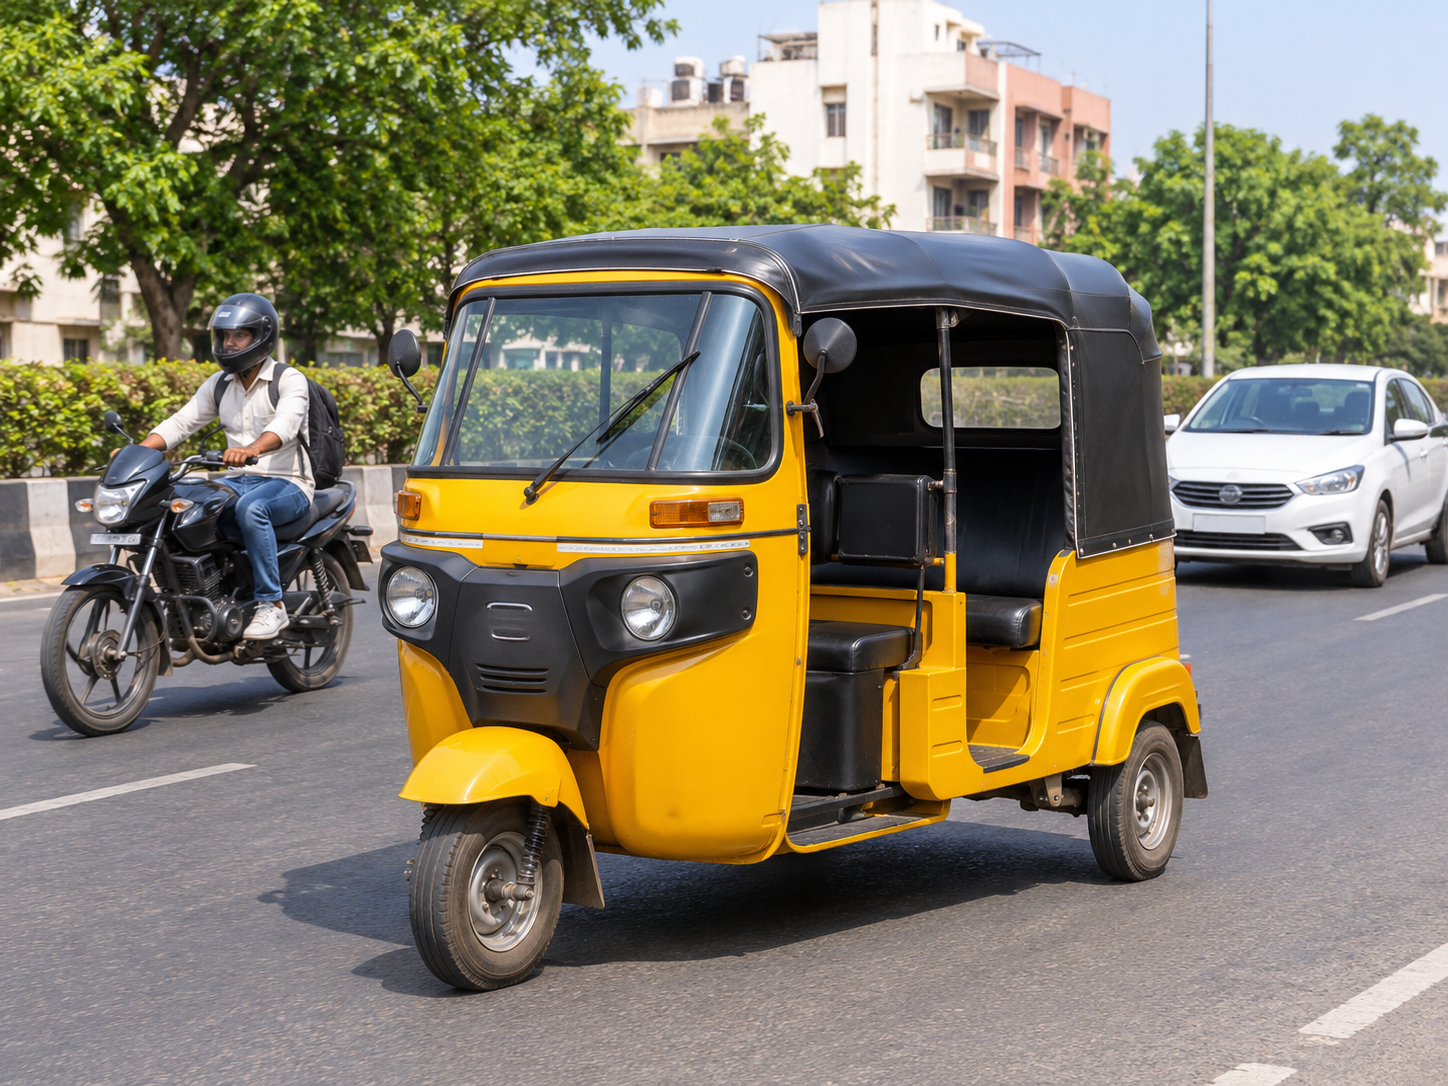

Uploaded: Vibrant Indian Street Traffic.png


In [7]:
from google.colab import files
from IPython.display import display

uploaded = files.upload()
if not uploaded:
    raise RuntimeError("Please upload an image and run this cell again.")

filename = next(iter(uploaded))
display(Image.open(io.BytesIO(uploaded[filename])).convert("RGB"))
print("Uploaded:", filename)

## 8. Send image to FastAPI inference endpoint

In [8]:
response = client.post(
    "/predict",
    files={"file": (filename, uploaded[filename], "application/octet-stream")}
)

print("HTTP Status:", response.status_code)
response.raise_for_status()
data = response.json()

print("\\nPREDICTION:", data["prediction"])
print("CONFIDENCE:", str(data["confidence_percent"]) + "%")
print("TOTAL PROCESSING TIME:", str(data["total_time_ms"]) + " ms")

HTTP Status: 200
\nPREDICTION: minibus
CONFIDENCE: 6.62%
TOTAL PROCESSING TIME: 2119.298 ms


## 9. Display complete inference request trace (main skill output)

In [9]:
print("=" * 62)
print("          VISIONPORT – INFERENCE REQUEST TRACE")
print("=" * 62)
print("Request ID:", data["request_id"])
print("Filename:", data["filename"])
print("HTTP Status:", data["http_status"])

print("\\nPREDICTION RESULT")
print("-" * 62)
print("Predicted class:", data["prediction"])
print("Confidence:", str(data["confidence_percent"]) + "%")
print("Original image size:", data["image_size"])

print("\\nSTAGE-BY-STAGE EXECUTION TRACE")
print("-" * 62)
for number, stage in enumerate(data["execution_trace"], start=1):
    print(f"\\nStage {number}: {stage['stage']}")
    print("Status:", stage["status"])
    if "filename" in stage:
        print("File:", stage["filename"])
        print("Bytes received:", stage["bytes_received"])
    if "image_size" in stage:
        print("Image dimensions:", stage["image_size"])
    if "tensor_shape" in stage:
        print("Tensor shape:", stage["tensor_shape"])
    if "model" in stage:
        print("Model:", stage["model"])
        print("Execution device:", stage["device"])
    if "time_ms" in stage:
        print("Processing time:", str(stage["time_ms"]) + " ms")

print("\\nTOTAL REQUEST TIME:", str(data["total_time_ms"]) + " ms")
print("=" * 62)

          VISIONPORT – INFERENCE REQUEST TRACE
Request ID: fc8b8498-8e6f-4daa-8ae2-9bdd223511f7
Filename: Vibrant Indian Street Traffic.png
HTTP Status: 200
\nPREDICTION RESULT
--------------------------------------------------------------
Predicted class: minibus
Confidence: 6.62%
Original image size: [1448, 1086]
\nSTAGE-BY-STAGE EXECUTION TRACE
--------------------------------------------------------------
\nStage 1: API Input
Status: Completed
File: Vibrant Indian Street Traffic.png
Bytes received: 2684098
Processing time: 0.643 ms
\nStage 2: Image Decoding
Status: Completed
Image dimensions: [1448, 1086]
Processing time: 95.42 ms
\nStage 3: Preprocessing
Status: Completed
Tensor shape: [1, 3, 224, 224]
Processing time: 44.421 ms
\nStage 4: Model Execution
Status: Completed
Model: MobileNetV2
Execution device: cuda
Processing time: 1978.708 ms
\nStage 5: Response
Status: Completed
\nTOTAL REQUEST TIME: 2119.298 ms


## 10. Result
The inference API received the uploaded image, decoded and preprocessed it, executed the pretrained MobileNetV2 model, and returned a prediction and confidence score. The execution trace records each stage's completion status and processing time.

**Note:** MobileNetV2 classifies the entire image into one ImageNet category. It does not separately detect every bus, car, motorcycle, or pedestrian.